# Non-audio metadata experiment

The `train.csv` file has metadata beyond the audio: latitude, longitude, recording rating, and collection source (XC vs iNat). Audio features alone gave me 0.893 macro ROC-AUC with Logistic Regression. Here I want to see if adding these non-audio features helps.

The intuition is that species have geographic ranges (lat/lon should carry signal), and rating is correlated with recording quality (higher rated = cleaner audio).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
import warnings
from pathlib import Path

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score, accuracy_score, roc_auc_score
from sklearn.preprocessing import LabelEncoder, StandardScaler

warnings.filterwarnings('ignore')

FEAT_DIR = Path('../features')
DATA_DIR = Path('../birdclef-2026')
FIG_DIR = Path('../figures')

## 1. Load data and apply the same filter as model_comparison

I use the SET_D features (180 features, the best feature set). The metadata in train.csv is in the same row order as the saved features, so I just need to apply the same valid-class mask (species with ≥ 2 samples).

In [2]:
X = np.load(FEAT_DIR / 'X_train_setD.npy')
y_raw = np.load(FEAT_DIR / 'y_train.npy', allow_pickle=True)
train = pd.read_csv(DATA_DIR / 'train.csv')

le = LabelEncoder()
y = le.fit_transform(y_raw)

counts = np.bincount(y)
valid_mask = np.isin(y, np.where(counts >= 2)[0])
X = X[valid_mask]
y = y[valid_mask]
train = train[valid_mask].reset_index(drop=True)

print(f'X: {X.shape}, y: {y.shape}, classes: {len(np.unique(y))}')

X: (35545, 180), y: (35545,), classes: 202


## 2. Build the metadata feature block

Four new features:
- `latitude` and `longitude` — where the recording was made
- `rating` — quality score from 0 to 5
- `is_inat` — binary indicator for iNat vs XC source (these have different recording styles)

I keep things simple. No fancy encoding.

In [3]:
lat = train['latitude'].values.reshape(-1, 1)
lon = train['longitude'].values.reshape(-1, 1)
rating = train['rating'].values.reshape(-1, 1)
is_inat = (train['collection'] == 'iNat').astype(int).values.reshape(-1, 1)

X_meta = np.hstack([lat, lon, rating, is_inat])
X_combined = np.hstack([X, X_meta])

print(f'X_meta: {X_meta.shape}')
print(f'X_combined: {X_combined.shape}')
print(f'Lat range: [{lat.min():.2f}, {lat.max():.2f}]')
print(f'Lon range: [{lon.min():.2f}, {lon.max():.2f}]')
print(f'Rating range: [{rating.min()}, {rating.max()}]')
print(f'iNat fraction: {is_inat.mean():.3f}')

X_meta: (35545, 4)
X_combined: (35545, 184)
Lat range: [-54.86, 69.58]
Lon range: [-159.66, 175.32]
Rating range: [0.0, 5.0]
iNat fraction: 0.352


## 3. Evaluation function

Same 5-fold stratified CV as the model comparison notebook, using Logistic Regression (the best model from notebook 05). StandardScaler is fit on the training fold only.

In [4]:
def compute_roc_auc(y_true, y_proba, classes):
    per_class = []
    for i, cls in enumerate(classes):
        mask = (y_true == cls)
        if mask.sum() > 0 and mask.sum() < len(y_true):
            per_class.append(roc_auc_score(mask.astype(int), y_proba[:, i]))
    return np.mean(per_class)


def evaluate(X_data, y_data, name):
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    accs, f1s, aucs = [], [], []
    total_time = 0
    for tr_idx, va_idx in skf.split(X_data, y_data):
        X_tr, X_va = X_data[tr_idx], X_data[va_idx]
        y_tr, y_va = y_data[tr_idx], y_data[va_idx]
        scaler = StandardScaler()
        X_tr = scaler.fit_transform(X_tr)
        X_va = scaler.transform(X_va)
        start = time.time()
        model = LogisticRegression(max_iter=1000, random_state=42, n_jobs=-1)
        model.fit(X_tr, y_tr)
        total_time += time.time() - start
        y_pred = model.predict(X_va)
        y_proba = model.predict_proba(X_va)
        accs.append(accuracy_score(y_va, y_pred))
        f1s.append(f1_score(y_va, y_pred, average='macro', zero_division=0))
        aucs.append(compute_roc_auc(y_va, y_proba, model.classes_))
    print(f'{name}: acc={np.mean(accs):.4f}±{np.std(accs):.4f} | f1={np.mean(f1s):.4f}±{np.std(f1s):.4f} | auc={np.mean(aucs):.4f}±{np.std(aucs):.4f} | {total_time:.0f}s')
    return {'name': name, 'acc': np.mean(accs), 'acc_std': np.std(accs),
            'f1': np.mean(f1s), 'f1_std': np.std(f1s),
            'auc': np.mean(aucs), 'auc_std': np.std(aucs), 'time': total_time}

## 4. Run both experiments

In [5]:
r1 = evaluate(X, y, 'Audio only')
r2 = evaluate(X_combined, y, 'Audio + metadata')

df = pd.DataFrame([r1, r2])
df.to_csv(FIG_DIR / 'metadata_comparison_results.csv', index=False)
print()
print(df.to_string(index=False))

Audio only: acc=0.3278±0.0030 | f1=0.2699±0.0066 | auc=0.8932±0.0036 | 80s


Audio + metadata: acc=0.3773±0.0038 | f1=0.3148±0.0101 | auc=0.9215±0.0043 | 75s

            name      acc  acc_std       f1   f1_std      auc  auc_std      time
      Audio only 0.327810 0.002982 0.269945 0.006602 0.893199 0.003636 80.171729
Audio + metadata 0.377268 0.003773 0.314752 0.010052 0.921543 0.004313 75.354162


## 5. Bar chart

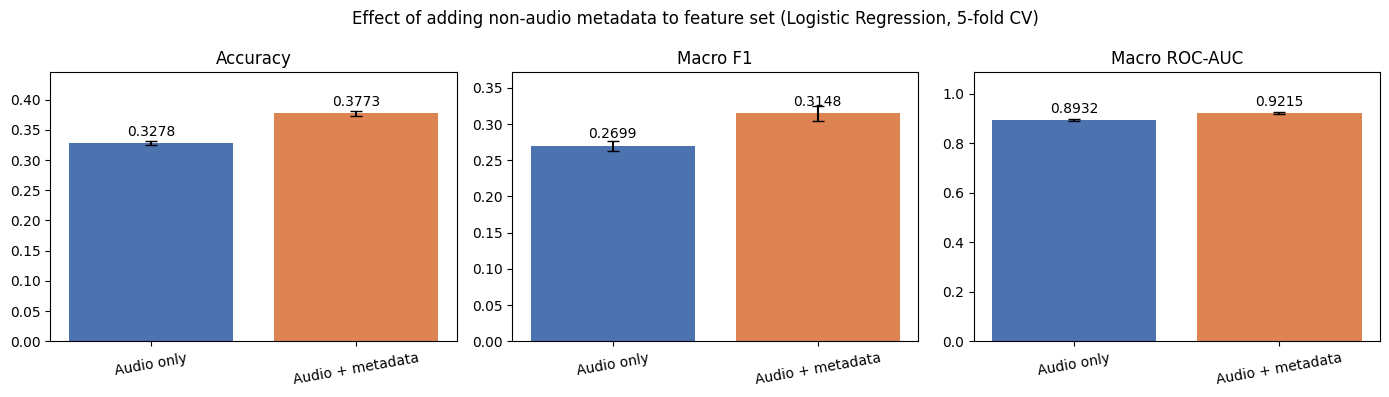

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
metrics = [('acc', 'acc_std', 'Accuracy'),
           ('f1', 'f1_std', 'Macro F1'),
           ('auc', 'auc_std', 'Macro ROC-AUC')]
colors = ['#4C72B0', '#DD8452']

for ax, (m, s, title) in zip(axes, metrics):
    vals = df[m].values
    errs = df[s].values
    bars = ax.bar(df['name'].values, vals, yerr=errs, capsize=4, color=colors)
    ax.set_title(title)
    ax.set_ylim(0, max(vals) * 1.18)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(vals)*0.02,
                f'{v:.4f}', ha='center', va='bottom', fontsize=10)
    ax.tick_params(axis='x', rotation=10)

plt.suptitle('Effect of adding non-audio metadata to feature set (Logistic Regression, 5-fold CV)')
plt.tight_layout()
plt.savefig(FIG_DIR / 'metadata_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Analysis

Adding the four metadata features pushed ROC-AUC from 0.893 to 0.922 — a solid improvement of almost 3 points. Accuracy went up even more, from 32.8% to 37.7%. This is more than I expected from just 4 extra features.

Why does this help so much? My guess is that latitude/longitude carries strong signal — species have geographic ranges, so knowing where a recording was made narrows down which species are likely to be there. Rating probably helps too because higher-rated recordings are cleaner (less background noise), so the audio features themselves are more reliable for those samples.

This is also a useful sanity check on the project framing. The prof mentioned non-audio features as a potential bonus direction, and the result confirms it was worth trying. It would be interesting to disentangle which of the four features contributes most — a quick follow-up would be to add them one at a time.

A caveat: in a real deployment, the test soundscapes also have known recording locations (the field recorders are at fixed sites), so this metadata is available at inference time and the experiment is realistic. The rating would not be available for unlabeled test recordings, but lat/lon would be.